# Waveguide reflection profiles

By default, Run All displays the existing CSV results. Set RUN_SIMULATIONS=True only to recompute and replace the selected calibration series.

**Setup:** from the repository root, run `conda env create -f environment.yml` then `conda activate single-photon-renorm`, then `jupyter lab`. Select that Python environment as the kernel. The first cell also supports running directly from the checkout.

**How to use:** run cells from top to bottom. Parameters are grouped before the simulation or plotting cells. Figures display inline; `SAVE_FIGURES=False` prevents overwriting exported PDFs. Units: ħ = c = 1. See `guide_utilisation.pdf` at the repository root for notation and the calibration workflow.


<h1> Experiment reflection against photon momentum </h1>

In [1]:
RUN_SIMULATIONS = False  # True recomputes the selected scan and writes its CSVs.
SAVE_FIGURES = True  # Set True to export the figures to results/fig.

# Run from the repository root or any of its subdirectories.
import sys
from pathlib import Path
project_root = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                     if (p / "src" / "experiment.py").is_file()), None)
if project_root is None:
    raise FileNotFoundError("Open Jupyter inside the single_photon_code checkout; see README.md.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
benchmark_root = project_root / "waveguide_model"
setup_root = project_root / "2d_setup"

#General imports
resol = 300
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "axes.linewidth": 0.7,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.direction": "in",
    "ytick.direction": "in",

    # Lines / markers
    "lines.linewidth": 1.0,
    "lines.markersize": 4,

})

import numpy as np
pi = np.pi


#Local imports
from waveguide_model.scripts_experiments.reflection_vs_frequency import run_reflection_vs_frequency
from waveguide_model.bare_param import get_bare_parameters

<h2> Execute the experiment </h2>

To assess the impact of the momentum cutoff window, we run the experiment several times. Each experiment corresponds to a given cutoff window $[\Lambda_{
m IR}, \Lambda_{
m UV}]$

In [2]:
#Parameters of the simulation
param_photon_bis = {'sigma_p': 0.05*np.pi, 'x_init': -25}  # p_0 will be varied in this experiment

Omega_A = 10*np.pi
gamma_A = np.pi
L = 100
param_cavity_physical = {'Omega_A': Omega_A, 'gamma_A': gamma_A, 'L': L}

param_time_evol = {'T': 50, 'dt': 0.01}

#Define an array of central momenta around the TLS resonance
nb_p0 = 21
p0_tab = np.linspace(Omega_A - gamma_A/2,
                     Omega_A + gamma_A/2, nb_p0)

#Assess the reflection curve for different momentum cutoff windows
cutoff_windows = [
    (0, 20*pi),
    (0, 14*pi),
    (8*pi, 14*pi),
    (9*pi, 11*pi),
]

Run the experiment for each momentum cutoff window

In [3]:
if RUN_SIMULATIONS:
    correction = True

    for i in range(len(cutoff_windows)):
        index_experiment = i+1
        print("Running cutoff window number ", index_experiment, " out of ", len(cutoff_windows))
        cutoffs = {'Omega_min': cutoff_windows[i][0], 'Omega_max': cutoff_windows[i][1]}
        Omega_0, gamma_0 = get_bare_parameters(Omega_A, gamma_A, cutoffs, correction=correction)
        param_cavity = {'Omega_0': Omega_0, 'gamma_0': gamma_0, 'L': L}
        #Run the experiment

        p0_values, final_reflection_tab = run_reflection_vs_frequency(param_photon_bis, param_cavity, param_time_evol, p0_tab, cutoffs,
                                                                      index_experiment=index_experiment, correction=correction, progress=True)
else:
    print("Using the existing CSV results; scan skipped.")

Using the existing CSV results; scan skipped.


## Plot the results

Run the imports and parameter cells, then either figure cell below. The simulation cell is optional when the CSV files already exist. Each figure cell loads its data and exports one vector PDF with the panel layout of the reference paper: individual axis labels and a shared legend below the plots. Insert at full text width (e.g. `\textwidth` in a `figure*` environment).

Layout reference: [coincidence_vs_frequency_results.ipynb](https://github.com/rpiron/calibration_twophoton_waveguideQED/blob/main/notebooks/coincidence_vs_frequency_results.ipynb).

### Uncorrected reflection — cutoff windows 1–4

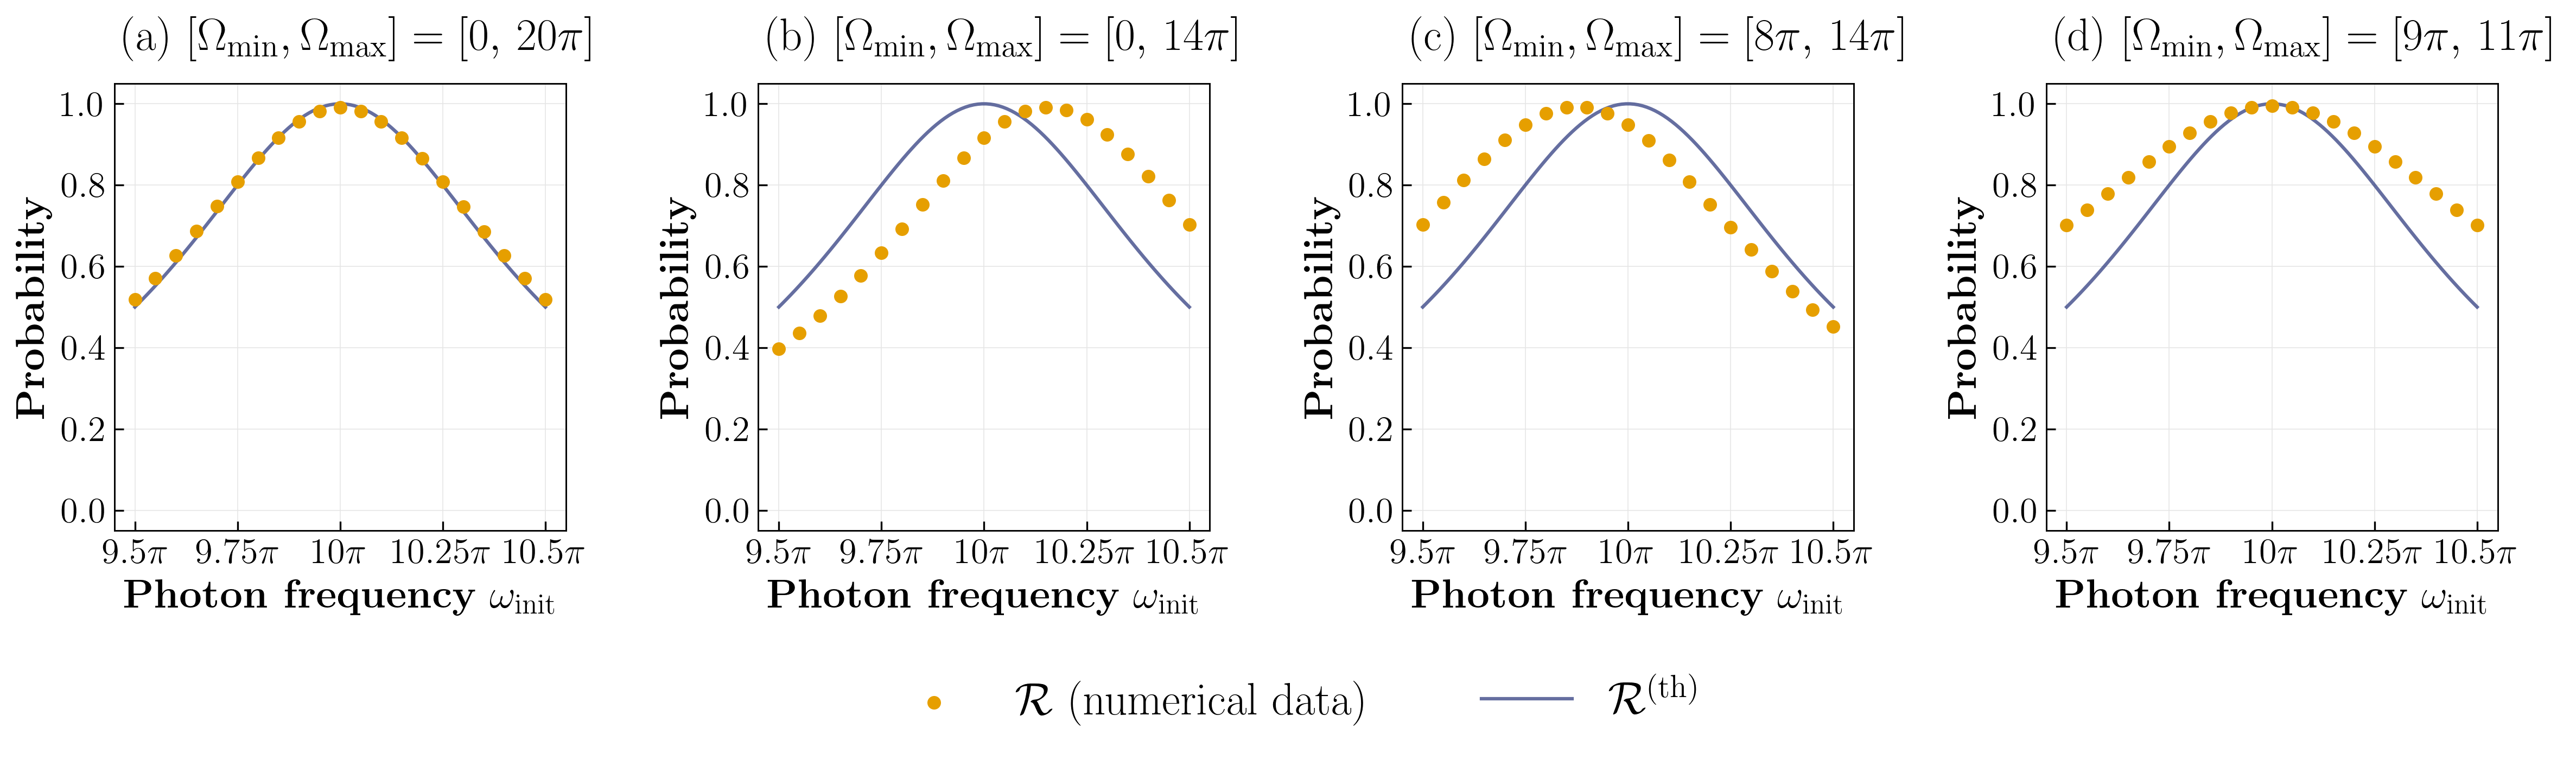

In [4]:
from src.plot_fonts import paper_fonts

# One cell = one full-width figure; data are read from the existing CSV files.
CSV_DIR = project_root / "waveguide_model/results/csv_files/reflection_vs_frequency"
FIG_DIR = project_root / "waveguide_model/results/fig/reflection_vs_frequency"
FIG_DIR.mkdir(parents=True, exist_ok=True)

p0_tab_theory = np.linspace(Omega_A - gamma_A/2, Omega_A + gamma_A/2, 100)
R_theory = 1 / (1 + ((p0_tab_theory - Omega_A) / (gamma_A/2))**2)

# Layout of the reference paper: individual axes, one-line panel labels, legend below.
# Font sizes account for reduction to approximately 18 cm in the article.
fig, axes = plt.subplots(1, 4, figsize=(16, 4), dpi=resol)

for index_experiment, ax in enumerate(axes, start=1):
    df = pd.read_csv(CSV_DIR / f"reflection_vs_frequency_{index_experiment}_uncorrected.csv")
    ax.scatter(df['photon_momentum_tab'], df['final_reflection_tab'],
               label=r'$\mathcal{R}$ (numerical data)', color='#E69F00', s=25, zorder=3)

    ax.plot(p0_tab_theory, R_theory, color='#3E4A89', lw=1.5, alpha=0.8,
            label=r'$\mathcal{R}^{(\rm th)}$', zorder=2)

    ir_cutoff, uv_cutoff = cutoff_windows[index_experiment - 1]
    ir_label = '0' if np.isclose(ir_cutoff, 0) else rf'{ir_cutoff/pi:g}\pi'
    uv_label = rf'{uv_cutoff/pi:g}\pi'
    ax.text(0.02, 1.05,
            rf'({"abcd"[index_experiment - 1]}) $[\Omega_{{\min}},\Omega_{{\max}}]=[{ir_label},\,{uv_label}]$',
            transform=ax.transAxes, fontsize=20, va='bottom')
    ax.set_xticks([Omega_A - gamma_A/2, Omega_A - gamma_A/4, Omega_A,
                  Omega_A + gamma_A/4, Omega_A + gamma_A/2],
                 [r'$9.5\pi$', r'$9.75\pi$', r'$10\pi$', r'$10.25\pi$', r'$10.5\pi$'])
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel(r'\textbf{Photon frequency} $\omega_{\mathrm{init}}$', fontsize=18)
    ax.set_ylabel(r'\textbf{Probability}', fontsize=18)
    ax.tick_params(axis='both', which='major', length=4, width=0.8, labelsize=16)
    ax.grid(color='0.9', linestyle='-', linewidth=0.4)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0),
           ncol=2, fontsize=20, frameon=False, handlelength=2, columnspacing=2.5)

fig.tight_layout()
# Adjust fonts only after the original layout has been computed.
paper_fonts(fig, 20, tick_size=18)
if SAVE_FIGURES:
    fig.savefig(FIG_DIR / 'reflection_multi_cutoff_experiment_uncorrected.pdf', dpi=resol, bbox_inches='tight', pad_inches=0.2)
plt.show()

### Corrected reflection — cutoff windows 1–4

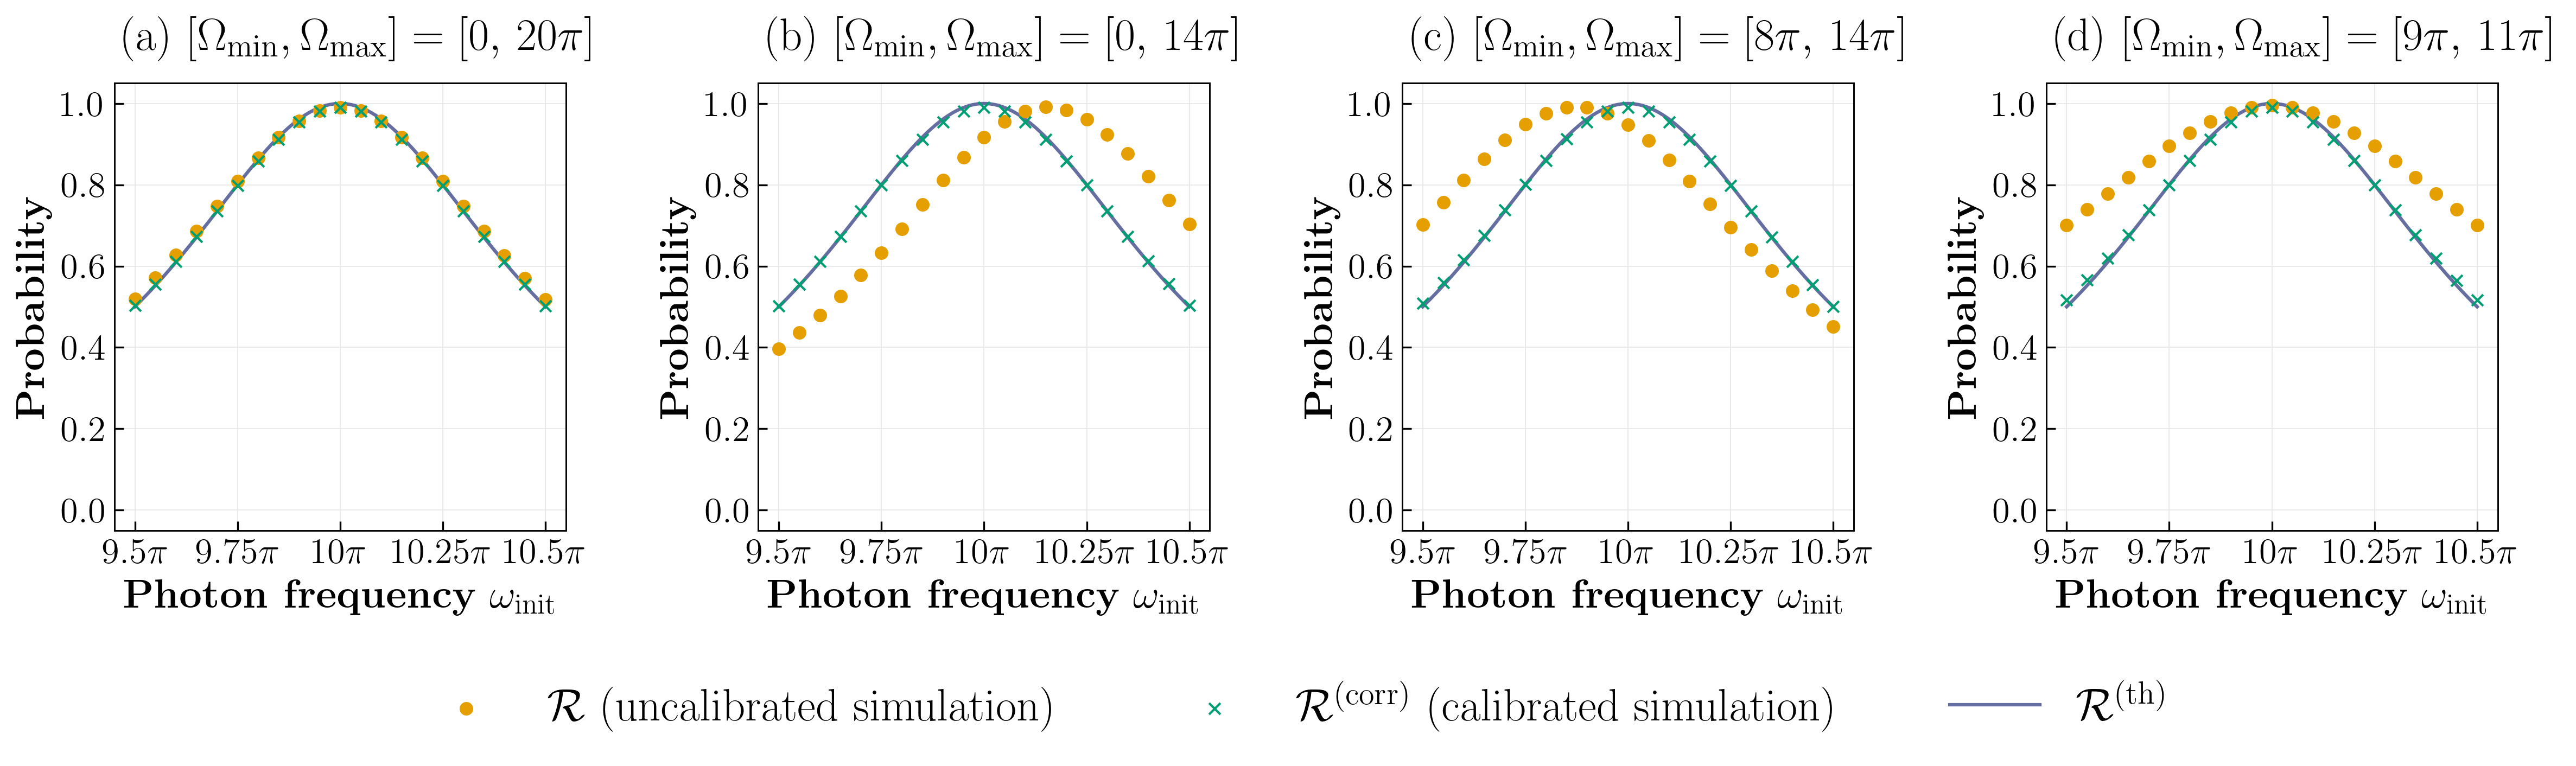

In [5]:
from src.plot_fonts import paper_fonts

# One cell = one full-width figure; data are read from the existing CSV files.
CSV_DIR = project_root / "waveguide_model/results/csv_files/reflection_vs_frequency"
FIG_DIR = project_root / "waveguide_model/results/fig/reflection_vs_frequency"
FIG_DIR.mkdir(parents=True, exist_ok=True)
p0_tab_theory = np.linspace(Omega_A - gamma_A/2, Omega_A + gamma_A/2, 100)
R_theory = 1 / (1 + ((p0_tab_theory - Omega_A) / (gamma_A/2))**2)

# Layout of the reference paper: individual axes, one-line panel labels, legend below.
# Font sizes account for reduction to approximately 18 cm in the article.
fig, axes = plt.subplots(1, 4, figsize=(16, 4), dpi=resol)

for index_experiment, ax in enumerate(axes, start=1):
    df = pd.read_csv(CSV_DIR / f"reflection_vs_frequency_{index_experiment}_uncorrected.csv")
    ax.scatter(df['photon_momentum_tab'], df['final_reflection_tab'],
               label=r'$\mathcal{R}$ (uncalibrated simulation)', color='#E69F00', s=25, zorder=3)
    df_corrected = pd.read_csv(CSV_DIR / f"reflection_vs_frequency_{index_experiment}_corrected.csv")
    ax.scatter(df_corrected['photon_momentum_tab'], df_corrected['final_reflection_tab'],
               label=r'$\mathcal{R}^{(\rm corr)}$ (calibrated simulation)', color='#009E73',
               s=25, marker='x', linewidths=1, zorder=4)
    ax.plot(p0_tab_theory, R_theory, color='#3E4A89', lw=1.5, alpha=0.8,
            label=r'$\mathcal{R}^{(\rm th)}$', zorder=2)

    ir_cutoff, uv_cutoff = cutoff_windows[index_experiment - 1]
    ir_label = '0' if np.isclose(ir_cutoff, 0) else rf'{ir_cutoff/pi:g}\pi'
    uv_label = rf'{uv_cutoff/pi:g}\pi'
    ax.text(0.02, 1.05,
            rf'({"abcd"[index_experiment - 1]}) $[\Omega_{{\min}},\Omega_{{\max}}]=[{ir_label},\,{uv_label}]$',
            transform=ax.transAxes, fontsize=20, va='bottom')
    ax.set_xticks([Omega_A - gamma_A/2, Omega_A - gamma_A/4, Omega_A,
                  Omega_A + gamma_A/4, Omega_A + gamma_A/2],
                 [r'$9.5\pi$', r'$9.75\pi$', r'$10\pi$', r'$10.25\pi$', r'$10.5\pi$'])
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel(r'\textbf{Photon frequency} $\omega_{\mathrm{init}}$', fontsize=18)
    ax.set_ylabel(r'\textbf{Probability}', fontsize=18)
    ax.tick_params(axis='both', which='major', length=4, width=0.8, labelsize=16)
    ax.grid(color='0.9', linestyle='-', linewidth=0.4)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0),
           ncol=3, fontsize=20, frameon=False, handlelength=2, columnspacing=2.5)
fig.tight_layout()
# Adjust fonts only after the original layout has been computed.
paper_fonts(fig, 20, tick_size=18)
if SAVE_FIGURES:
    fig.savefig(FIG_DIR / 'reflection_multi_cutoff_experiment_corrected.pdf', dpi=resol, bbox_inches='tight', pad_inches=0.2)
plt.show()